This notebook will serve to generate bathymetric surfaces from hydrographic soundings. As of 27 MAY 26, I am thinking of making this an ablation study where I increase the complexity of the SVGP. At first we start with a base SVGP, then add ARD to the kernel to adjust for anisotropic soundings, and then introduce an MLP for kernel warping to adjust for non-stationarity in the soundings.

In [1]:
%reload_ext autoreload
%autoreload 2
import os
import sys
sys.path.insert(0, os.path.abspath('../src'))
import pandas as pd
import geopandas as gpd
from pathlib import Path
import sklearn
import numpy as np
import fiona
import matplotlib.pyplot as plt
import contextily as cx
from shapely import contains_xy

import processing_help
import tqdm
import rasterio
from rasterio.warp import transform_bounds
from rasterio.transform import from_origin
from rasterio.features import geometry_mask
import torch
import gpytorch
from torch.utils.data import TensorDataset, DataLoader

from gpytorch.models import ApproximateGP
from gpytorch.variational import CholeskyVariationalDistribution
from gpytorch.variational import VariationalStrategy
from gpytorch.constraints import Interval, GreaterThan, LessThan
from gpytorch.priors import GammaPrior, LogNormalPrior, UniformPrior, NormalPrior
from gpytorch.means import Mean

from scipy.interpolate import LinearNDInterpolator, NearestNDInterpolator


# Check device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

Using device: cuda
GPU: NVIDIA GeForce RTX 4070
Memory: 12.5 GB


In [2]:
WORK_DIR = Path('/mnt/teamgroup/AutoDBM/source_data')   # linux
# WORK_DIR = Path('/mnt/c/Users/clayc/Documents/AutoDBM/raw_data')     # wsl2

survey_gdbs = list(WORK_DIR.glob('*/*/*.gdb'))
len(survey_gdbs)

10346

In [3]:
geojson = Path(os.getcwd()).parent / 'National_Channel_Framework_-6742069550782745925.geojson'
ncf = gpd.read_file(geojson)

## First, map the survey we are processing and visualize the histrogram of the soundings

/mnt/teamgroup/AutoDBM/source_data/CESAM/CESAM_TTW_TT_05_COL_20240417_CS_06/TT_05_COL_20240417_CS_06.gdb


/home/clayc/git_repos/sounding2surface/.pixi/envs/default/lib/python3.12/site-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D Point' is converted to 'Point Z'
  return ogr_read(


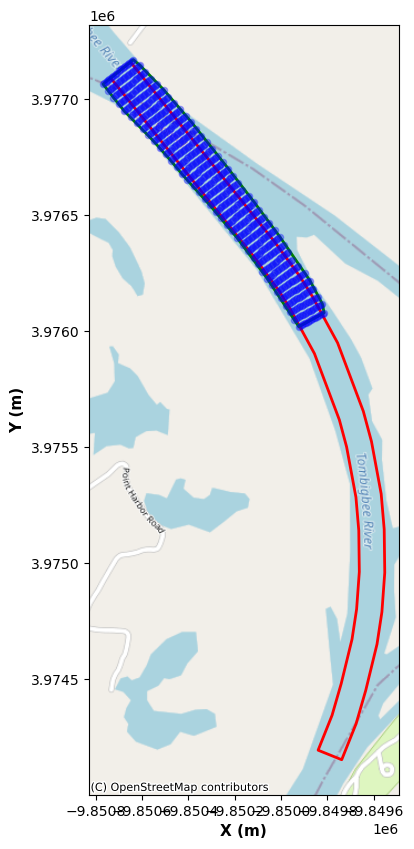

In [4]:
survey = survey_gdbs[np.random.randint(0, len(survey_gdbs)-1, size=1)[0]]
print(survey)
survey_bounds = gpd.read_file(survey, layer='SurveyJob')

if 'SurveyPoint_HD' in fiona.listlayers(survey):
    points = gpd.read_file(survey, layer='SurveyPoint_HD')
else:
    points = gpd.read_file(survey, layer='SurveyPoint')

# Keep everything in survey CRS for modeling + raster output.
survey_crs = survey_bounds.crs
if points.crs != survey_crs:
    points = points.to_crs(survey_crs)
if ncf.crs != survey_crs:
    ncf = ncf.to_crs(survey_crs)

# Preserve names used in downstream inspection cells.
survey_polygons = survey_bounds.copy()
ncf_polygons = ncf.copy()

xy_raw = np.column_stack([points.geometry.x, points.geometry.y])
z_raw = points.Z_use.values

# Create temporary Web Mercator layers only for basemap visualization.
survey_polygons_3857 = survey_bounds.to_crs(epsg=3857)
ncf_polygons_3857 = ncf.to_crs(epsg=3857)
points_3857 = points.to_crs(epsg=3857)

ncf_polygons_3857 = ncf_polygons_3857[ncf_polygons_3857.intersects(points_3857.union_all())]
survey_polygons_3857 = survey_polygons_3857[survey_polygons_3857.intersects(points_3857.union_all())]

fig, ax = plt.subplots(figsize=(10, 10))
ncf_polygons_3857.plot(ax=ax, facecolor='none', edgecolor='red', linewidth=2)
survey_polygons_3857.plot(ax=ax, facecolor='none', edgecolor='green', linewidth=2)
points_3857.plot(ax=ax, color='blue', markersize=20, alpha=0.3)

cx.add_basemap(ax, source=cx.providers.OpenStreetMap.Mapnik)
ax.set_xlabel('X (m)', fontsize=11, fontweight='bold')
ax.set_ylabel('Y (m)', fontsize=11, fontweight='bold')

plt.show()

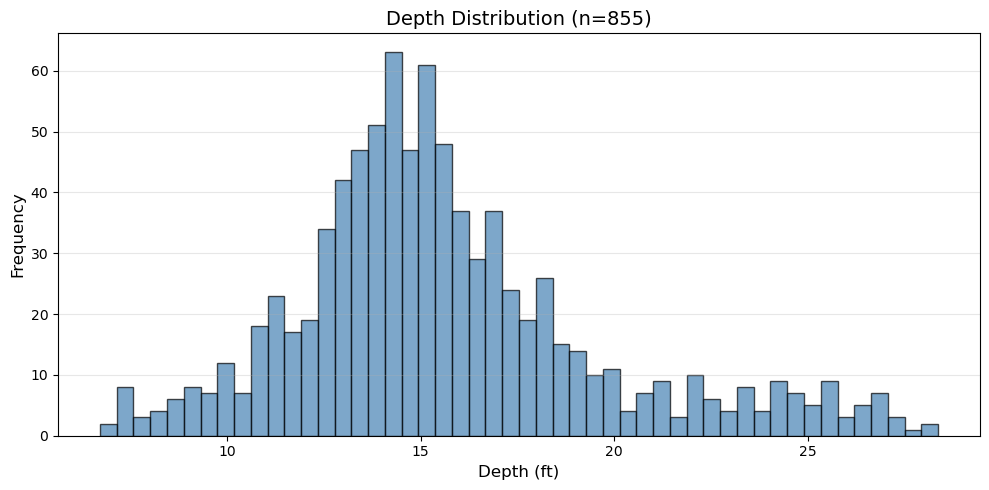


Depth Statistics (n=855):
  Mean: 15.64 ft
  Std: 4.00 ft
  Min: 6.72 ft
  Max: 28.36 ft


In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

# Histogram for z_raw
ax.hist(z_raw, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Depth (ft)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'Depth Distribution (n={len(z_raw):,})', fontsize=14)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"\nDepth Statistics (n={len(z_raw):,}):")
print(f"  Mean: {np.mean(z_raw):.2f} ft")
print(f"  Std: {np.std(z_raw):.2f} ft")
print(f"  Min: {np.min(z_raw):.2f} ft")
print(f"  Max: {np.max(z_raw):.2f} ft")

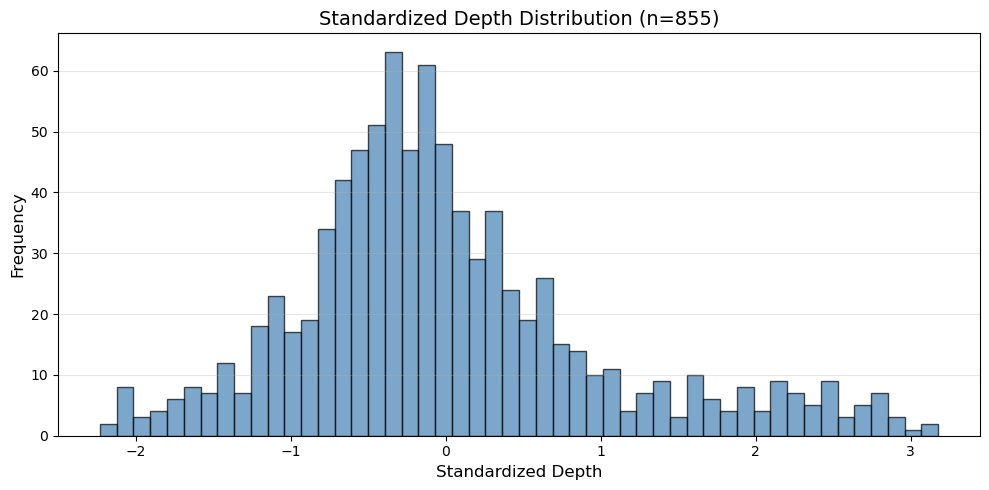

Standardized Depth Statistics (n=855):
  Mean: -0.00
  Std: 1.00
  Min: -2.23
  Max: 3.18


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

z_norm = (z_raw - np.mean(z_raw)) / np.std(z_raw)

# Histogram for z_norm
ax.hist(z_norm, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Standardized Depth', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'Standardized Depth Distribution (n={len(z_norm):,})', fontsize=14)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Standardized Depth Statistics (n={len(z_norm):,}):")
print(f"  Mean: {np.mean(z_norm):.2f}")
print(f"  Std: {np.std(z_norm):.2f}")
print(f"  Min: {np.min(z_norm):.2f}")
print(f"  Max: {np.max(z_norm):.2f}")

# Next, implement a spatial Gaussian Process to generate bathymetric surfaces from the soundings
- If soundings > 2000 points, regular GP
- If soundings < 2000 points, stochastic variational GP

### 27 MAY 26: Testing spline warping similar to https://doi.org/10.1016/j.cageo.2022.105056

- In place of normalization, using a spline could be a more robust method to get zero-meaned data for GP inference

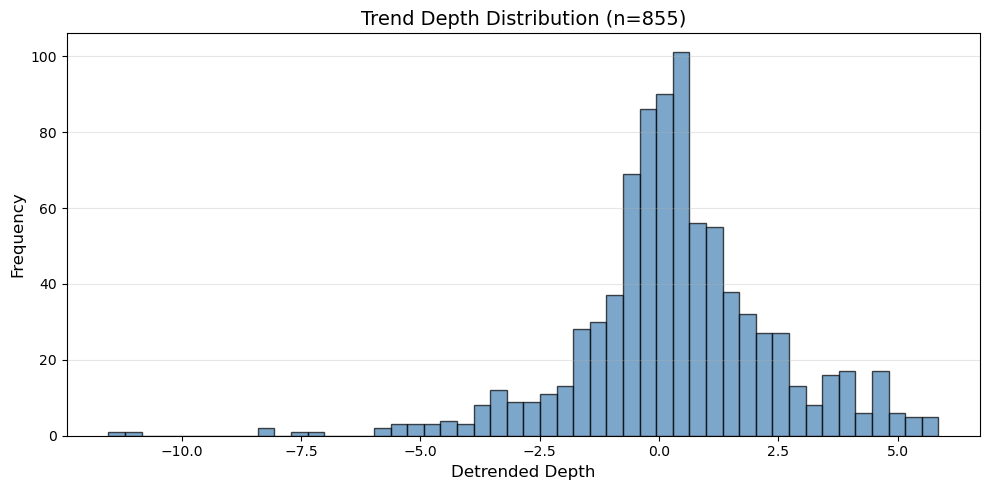

Detrended Depth Statistics (n=855):
  Mean: 0.35
  Std: 2.09
  Min: -11.54
  Max: 5.85


In [7]:
# TODO: implement a verde spline and look to see if it will better zero-mean the data compared to normalization
import verde as vd

# trend = vd.Trend(degree=2).fit((xy_raw[:, 0], xy_raw[:, 1]), z_raw)
# residuals = z_raw - trend.predict((xy_raw[:, 0], xy_raw[:, 1]))

chain = vd.Chain([
    ("reduce", vd.BlockMean(spacing=50)),   # adjust spacing to your CRS units
    ("spline", vd.Spline(damping=1e-4)),
])
chain.fit((xy_raw[:, 0], xy_raw[:, 1]), z_raw)
trend_pred = chain.predict((xy_raw[:, 0], xy_raw[:, 1]))   # evaluate at full resolution
residuals = z_raw - trend_pred

fig, ax = plt.subplots(figsize=(10, 5))

# Histogram for residuals
ax.hist(residuals, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Detrended Depth', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'Trend Depth Distribution (n={len(residuals):,})', fontsize=14)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Detrended Depth Statistics (n={len(residuals):,}):")
print(f"  Mean: {np.mean(residuals):.2f}")
print(f"  Std: {np.std(residuals):.2f}")
print(f"  Min: {np.min(residuals):.2f}")
print(f"  Max: {np.max(residuals):.2f}")

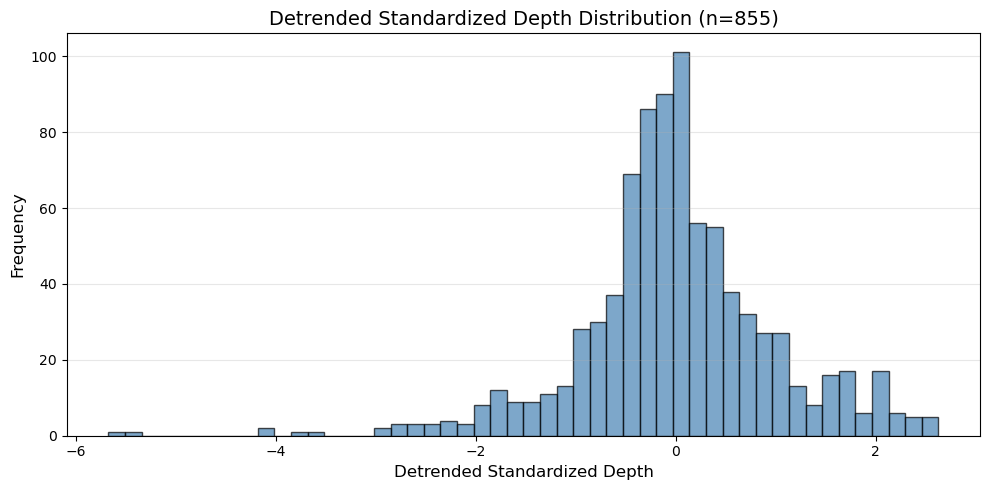

Detrended Standardized Depth Statistics (n=855):
  Mean: -0.00
  Std: 1.00
  Min: -5.67
  Max: 2.63


In [8]:
fig, ax = plt.subplots(figsize=(10, 5))

residuals_norm = (residuals - np.mean(residuals)) / np.std(residuals)

# Histogram for residuals_norm
ax.hist(residuals_norm, bins=50, color='steelblue', edgecolor='black', alpha=0.7)
ax.set_xlabel('Detrended Standardized Depth', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)
ax.set_title(f'Detrended Standardized Depth Distribution (n={len(residuals_norm):,})', fontsize=14)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Detrended Standardized Depth Statistics (n={len(residuals_norm):,}):")
print(f"  Mean: {np.mean(residuals_norm):.2f}")
print(f"  Std: {np.std(residuals_norm):.2f}")
print(f"  Min: {np.min(residuals_norm):.2f}")
print(f"  Max: {np.max(residuals_norm):.2f}")

## Develop spatial GP for generating surfaces

In [9]:
# should be 10 ft spatial resolution for the outputs
grid_res = 10.0 

# 1. Train on the full dataset
X_all = torch.as_tensor(xy_raw, dtype=torch.float32)
y_all = torch.as_tensor(residuals_norm, dtype=torch.float32)

# Standardize
x_mean = X_all.mean(0)
x_std = X_all.std(0).clamp_min(1e-6)
X_all_scaled = (X_all - x_mean) / x_std

if torch.cuda.is_available():
    X_all_scaled = X_all_scaled.cuda().float()
    y_all = y_all.cuda().float()
xy_raw = np.asarray(xy_raw, dtype=np.float32)
x_min, x_max = float(xy_raw[:, 0].min()), float(xy_raw[:, 0].max())
y_min, y_max = float(xy_raw[:, 1].min()), float(xy_raw[:, 1].max())

nx = int(np.ceil((x_max - x_min) / grid_res)) + 1
ny = int(np.ceil((y_max - y_min) / grid_res)) + 1
x_grid = np.linspace(x_min, x_min + (nx - 1) * grid_res, nx, dtype=np.float32)
y_grid = np.linspace(y_min, y_min + (ny - 1) * grid_res, ny, dtype=np.float32)

transform = from_origin(
    x_min - grid_res / 2,
    y_max + grid_res / 2,
    grid_res, grid_res
)

grid_xx, grid_yy = np.meshgrid(x_grid, y_grid)  # shape (ny, nx) by default
grid_points = torch.stack([
    torch.tensor(grid_xx.flatten(), dtype=torch.float32),
    torch.tensor(grid_yy.flatten(), dtype=torch.float32)
], dim=1)

grid_points_s = (grid_points - x_mean.cpu()) / x_std.cpu()

In [10]:
grid_points_s

tensor([[-1.8942, -1.9377],
        [-1.8798, -1.9377],
        [-1.8654, -1.9377],
        ...,
        [ 1.8517,  1.7330],
        [ 1.8661,  1.7330],
        [ 1.8805,  1.7330]])

In [ ]:
all_train_dataset = TensorDataset(X_all_scaled, y_all)
# all_train_loader = DataLoader(all_train_dataset, batch_size=1024, shuffle=True)

all_train_loader = DataLoader(
    all_train_dataset,
    batch_size=2048, 
    shuffle=True,
    num_workers=0 # Keep at 0 since data is already on GPU
)

In [ ]:
class TINMean(Mean):
    def __init__(self, xy, z):
        super().__init__()
        xy = xy.detach().cpu().numpy()
        z = z.detach().cpu().numpy()
        self._lin = LinearNDInterpolator(xy, z)
        self._near = NearestNDInterpolator(xy, z)

    def forward(self, x):
        shape = x.shape[:-1]
        xy = x.detach().cpu().numpy().reshape(-1, x.shape[-1])
        m = self._lin(xy)
        nan = np.isnan(m)
        if nan.any():
            m[nan] = self._near(xy[nan])
        return torch.as_tensor(m, dtype=x.dtype, device=x.device).reshape(shape)

class GPModel(ApproximateGP):
    def __init__(self, inducing_points, train_x, train_z):
        variational_distribution = CholeskyVariationalDistribution(inducing_points.size(0))
        variational_strategy = VariationalStrategy(
            self, inducing_points, variational_distribution,
            learn_inducing_locations=True,
        )
        super().__init__(variational_strategy)

        # TODO: Try out different mean functions
        # Maybe even try some of the means with first and second derivatives?
        
        # self.mean_module = TINMean(train_x, train_z)      # NOTE: if using the TIN mean, the GP is smoothing the TIN instead of learning to predict the depth. So GP is used to remove artifacats and noise generated by TIN interpolation
        self.mean_module = gpytorch.means.ZeroMean()
        # self.mean_module = gpytorch.means.ConstantMean()      # NOTE: this one is probably redundant since pre-processing has been done to confirm a mean of zero
        # self.mean_module = gpytorch.means.LinearMean(input_size=2)

        ext = (train_x.max(dim=0).values - train_x.min(dim=0).values).detach().cpu()
        dmin, dmax = float(ext.min()), float(ext.max())

        self.covar_short = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.MaternKernel(
                nu=1.5, ard_num_dims=2,
                lengthscale_constraint=Interval(dmin * 0.005, dmin * 0.10),
            ),
            outputscale_prior=GammaPrior(2.0, 4.0),
        )
        self.covar_long = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.MaternKernel(
                nu=2.5, ard_num_dims=2,
                lengthscale_constraint=Interval(dmin * 0.10, dmax * 0.50),  
            ),
            outputscale_prior=GammaPrior(2.0, 4.0),
        )

        self.covar_short.base_kernel.lengthscale = dmin * 0.03
        self.covar_long.base_kernel.lengthscale = dmin * 0.20
        self.covar_short.outputscale = 0.1
        self.covar_long.outputscale = 0.1

    def forward(self, x):
        mean_x = self.mean_module(x)
        covar_x = self.covar_short(x) + self.covar_long(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, covar_x)

In [ ]:
# TODO: Make the number of inducing points an input when pushing to HPC

from sklearn.cluster import MiniBatchKMeans

X_unique = torch.unique(X_all_scaled, dim=0)

# TODO: refine this so that if there are less than 3000 points, an exact GP is used instead of an SVGP
# TODO: also, maybe have it increase for huge datasets. 

# 2. Smarter Inducing Point Initialization (Run once)
# This ensures m points cover the survey area better than random sampling
def init_inducing_points(X, n_inducing=3000):
    # Use MiniBatchKMeans on CPU for speed, then move back to the active device
    kmeans = MiniBatchKMeans(n_clusters=n_inducing, batch_size=10000, n_init=3, random_state=42)
    kmeans.fit(X.detach().cpu().numpy())
    centers = torch.tensor(kmeans.cluster_centers_, dtype=torch.float32)

    # Tiny perturbation helps avoid near-duplicate inducing locations that can destabilize Kzz
    centers = centers + 1e-5 * torch.randn_like(centers)
    return centers.to(X.device)

num_inducing = min(2000, X_unique.size(0))
inducing_points = init_inducing_points(X_unique, num_inducing)

In [ ]:
# model = GPModel(inducing_points=inducing_points)

train_x_all, train_y_all = all_train_loader.dataset.tensors   # (N,2) coords, (N,) depths

model = GPModel(inducing_points=inducing_points,
                train_x=train_x_all, train_z=train_y_all)

likelihood = gpytorch.likelihoods.GaussianLikelihood()

if torch.cuda.is_available():
    model = model.cuda()
    likelihood = likelihood.cuda()

# Enforce a noise floor (prevents near-singular covariance)
likelihood.noise_covar.register_constraint(
    "raw_noise", gpytorch.constraints.GreaterThan(1e-4)
)

variational_params = set(model.variational_strategy._variational_distribution.parameters())
hyper_params = [p for p in model.parameters() if p not in variational_params] + \
               list(likelihood.parameters())

variational_ngd_optimizer = gpytorch.optim.NGD(
    model.variational_strategy._variational_distribution.parameters(),
    num_data=y_all.size(0),
    lr=0.01, 
)

hyperparameter_optimizer = torch.optim.Adam(hyper_params, lr=0.01)

In [ ]:
num_epochs = 50

model.train()
likelihood.train()

optimizer = torch.optim.Adam([
    {'params': model.parameters()},
    {'params': likelihood.parameters()},
], lr=0.01)

# Our loss object. We're using the VariationalELBO
mll = gpytorch.mlls.VariationalELBO(likelihood, model, num_data=y_all.size(0))

epochs_iter = tqdm.notebook.tqdm(range(num_epochs), desc="Epoch")
with gpytorch.settings.cholesky_jitter(1e-4), gpytorch.settings.variational_cholesky_jitter(1e-4), gpytorch.settings.cholesky_max_tries(10):
    for i in epochs_iter:
        # Within each iteration, we will go over each minibatch of data
        minibatch_iter = tqdm.notebook.tqdm(all_train_loader, desc="Minibatch", leave=False)
        for x_batch, y_batch in minibatch_iter:
            optimizer.zero_grad()
            output = model(x_batch)
            loss = -mll(output, y_batch)
            minibatch_iter.set_postfix(loss=loss.item())
            loss.backward()
            optimizer.step()

In [ ]:
model.eval()
likelihood.eval()
pred_means = []
pred_stds = []

with torch.no_grad(), gpytorch.settings.fast_pred_var():
    for i in range(0, grid_points_s.size(0), 2048):
        batch = grid_points_s[i:i+2048].cuda() if torch.cuda.is_available() else grid_points_s[i:i+2048]
        preds = likelihood(model(batch))
        # preds = model(batch)
        pred_means.append(preds.mean.cpu())
        pred_stds.append(preds.stddev.cpu())

pred_means = torch.cat(pred_means)
pred_stds = torch.cat(pred_stds)

# 4. Convert back to real units
z_grid = pred_means * np.std(residuals) + np.mean(residuals)
z_uncertainty = pred_stds * np.std(residuals)

trend_pred_grid = chain.predict((grid_points[:, 0].numpy(), grid_points[:, 1].numpy()))
z_grid_true = z_grid.numpy() + trend_pred_grid

# 5. Reshape to 2D grid
z_surface = z_grid_true.reshape(grid_xx.shape)
z_unc_surface = z_uncertainty.reshape(grid_xx.shape)

grid_np = grid_points.numpy()
mask = contains_xy((survey_bounds).union_all(), grid_np[:, 0], grid_np[:, 1])

# Apply mask to predictions.
z_grid_masked = z_grid_true
z_unc_masked = z_uncertainty
z_grid_masked[~mask] = np.nan
z_unc_masked[~mask] = np.nan

# Reshape back to 2D arrays aligned with transform/from_origin.
z_surface_masked = z_grid_masked.reshape(grid_xx.shape)
z_unc_surface_masked = z_unc_masked.reshape(grid_xx.shape)
 
z_raster = np.flipud(z_surface_masked).astype(np.float32)
z_unc_raster = np.flipud(z_unc_surface_masked).astype(np.float32)

In [ ]:
likelihood.noise

In [ ]:
# Reproject raster extent from survey CRS to Web Mercator.
x_min_3857, y_min_3857, x_max_3857, y_max_3857 = transform_bounds(
    survey_crs, "EPSG:3857", x_min, y_min, x_max, y_max
)
extent_3857 = [x_min_3857, x_max_3857, y_min_3857, y_max_3857]

# plot predictions and prediction uncertainty
fig, axes = plt.subplots(1, 2, figsize=(18, 9), dpi=150)

im1 = axes[0].imshow(
    np.flipud(z_raster), origin="lower", extent=extent_3857,
    cmap="terrain", alpha=0.7, zorder=2
)

ncf_polygons_3857.plot(ax=axes[0], facecolor='none', edgecolor='red',
                       linewidth=2, zorder=3)
cx.add_basemap(axes[0], source=cx.providers.OpenStreetMap.Mapnik,
               crs="EPSG:3857", zorder=1)
axes[0].set_xlim(extent_3857[0], extent_3857[1])
axes[0].set_ylim(extent_3857[2], extent_3857[3])
axes[0].set_title("SVGP Interpolation (Depth)")
axes[0].set_xlabel("Easting (m, Web Mercator)")
axes[0].set_ylabel("Northing (m, Web Mercator)")
fig.colorbar(im1, ax=axes[0], label="Depth (ft)", shrink=0.8)


im2 = axes[1].imshow(
    np.flipud(z_unc_raster), origin="lower", extent=extent_3857,
    cmap="magma_r", alpha=0.7, zorder=2
)

ncf_polygons_3857.plot(ax=axes[1], facecolor='none', edgecolor='red',
                       linewidth=2, zorder=3)
cx.add_basemap(axes[1], source=cx.providers.OpenStreetMap.Mapnik,
               crs="EPSG:3857", zorder=1)
axes[1].set_xlim(extent_3857[0], extent_3857[1])
axes[1].set_ylim(extent_3857[2], extent_3857[3])
axes[1].set_title("SVGP Predictive Uncertainty (1σ)")
axes[1].set_xlabel("Easting (m, Web Mercator)")
axes[1].set_ylabel("Northing (m, Web Mercator)")
fig.colorbar(im2, ax=axes[1], label="Uncertainty (ft)", shrink=0.8)

plt.tight_layout()
plt.show()

In [ ]:
# Extract raster predictions at the original point locations
# Uses nearest raster cell lookup based on the existing affine transform.
xs = xy_raw[:, 0]
ys = xy_raw[:, 1]

rows, cols = rasterio.transform.rowcol(transform, xs, ys)

z_interp_points = np.full(xs.shape[0], np.nan, dtype=np.float32)

rows = np.asarray(rows)
cols = np.asarray(cols)

in_bounds = (
    (rows >= 0) & (rows < z_raster.shape[0]) &
    (cols >= 0) & (cols < z_raster.shape[1])
)

z_interp_points[in_bounds] = z_raster[rows[in_bounds], cols[in_bounds]]

# Convenience wrapper using your existing notebook variables
def run_current_prediction_diagnostics(**kwargs):
    return processing_help.run_line_diagnostics(
        z_pred=z_interp_points,       
        z_true=z_raw,
        xy_coords=xy_raw,
        **kwargs,
    )

# Example (fast):
# metrics = run_current_prediction_diagnostics(make_plots=True, moran_sample=20000)
# Example (full):
metrics = run_current_prediction_diagnostics(make_plots=True, moran_sample=None, plot_sample=None)

In [ ]:
errors = z_interp_points - z_raw

print(f'Test MAE: {np.nanmean(abs(errors)):2f} ft')
print(f'Test NMAD: {1.4826 * np.nanmedian(abs(errors - np.nanmedian(errors))):2f} ft')
print(f'Test RMSE: {np.sqrt(np.nanmean(abs(errors)**2)):2f} ft')
print(f'Test Mean Error: {np.nanmean(errors):2f} ft')

In [ ]:
# export bathymetric surface

meta = {
    'driver': 'GTiff',
    'height': z_raster.shape[0],
    'width': z_raster.shape[1],
    'count': 1,
    'dtype': 'float32',
    'crs': survey_crs,
    'transform': transform,
    'nodata': -9999,
    'tiled': True,
    'blockxsize': 512,
    'blockysize': 512,
    'compress': 'deflate',
    'predictor': 3,
    'zlevel': 6
}

with rasterio.open(OUT_DIR / 'SVGP_depth.tif', 'w', **meta) as dst:
    dst.write(z_raster, 1)
    dst.build_overviews([2, 4, 8, 16, 32], rasterio.enums.Resampling.average)

with rasterio.open(OUT_DIR / 'SVGP_uncertainty.tif', 'w', **meta) as dst:
    dst.write(z_unc_raster, 1)
    dst.build_overviews([2, 4, 8, 16, 32], rasterio.enums.Resampling.average)